# Results: Problem 2

PCA-based anomaly detection from `src/problem2/main.py` (files in `results/problem2/`). Everything is fitted on the reference set only.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Problem 2 modules, used to recompute per-record scores for the plots.
sys.path.insert(0, "../src/problem2")
from data_utils import load_data, Preprocessor
from pca import PCA
from anomaly import PCAAnomalyScorer

BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
MID_GRAY, TEXT, TEXT_2, GRID = "#f0efec", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": TEXT_2, "axes.labelcolor": TEXT,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "axes.titlelocation": "left",
})
from matplotlib.colors import LinearSegmentedColormap
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, MID_GRAY, RED])

RESULTS = "../results/problem2/"
explained = pd.read_csv(RESULTS + "explained_variance.csv")
top10 = pd.read_csv(RESULTS + "top10_anomalies.csv")

## 1. Summary

In [2]:
print(open(RESULTS + "summary.txt").read())

X_reference: (915, 8), X_query: (246, 8)
features: conductivity, sodium, chloride, sulfate, ph, color, turbidity, toc

(2b) Explained variance
  PC1: 0.3592 (35.92%)   cumulative: 0.3592 (35.92%)
  PC2: 0.2017 (20.17%)   cumulative: 0.5609 (56.09%)

(2b) PC1: three largest absolute coefficients
  conductivity +0.5236
  sulfate      +0.4552
  sodium       +0.4508
  all PC1 coefficients: conductivity +0.524, sodium +0.451, chloride +0.370, sulfate +0.455, ph +0.377, color -0.188, turbidity +0.024, toc +0.015

(2d) Threshold tau = 95% quantile of the reference scores = 19.7148
  reference records above tau: 46 / 915
  flagged query records: 37 / 246

(2d) Ten highest-scoring query records
  rank  record_id          score  flagged
     1  Wd0ff3918e355     65.142  True
     2  Wda7c4446ab56     59.781  True
     3  Wfcd3c52dacfc     55.785  True
     4  We39fa2ed29ab     54.435  True
     5  We7e67de2c269     47.671  True
     6  Wfaca0e1ab9b2     46.362  True
     7  Wce50b72ffd36     46.

## 2. Explained variance (2b)

The first two components explain 56% of the variance.

,component,eigenvalue,explained_variance_ratio,cumulative_ratio
0,PC1,2.8769,0.3592,0.3592
1,PC2,1.6154,0.2017,0.5609
2,PC3,1.0179,0.1271,0.6880
3,PC4,0.9520,0.1189,0.8069
4,PC5,0.6064,0.0757,0.8826
5,PC6,0.3917,0.0489,0.9315
6,PC7,0.3260,0.0407,0.9722
7,PC8,0.2225,0.0278,1.0000


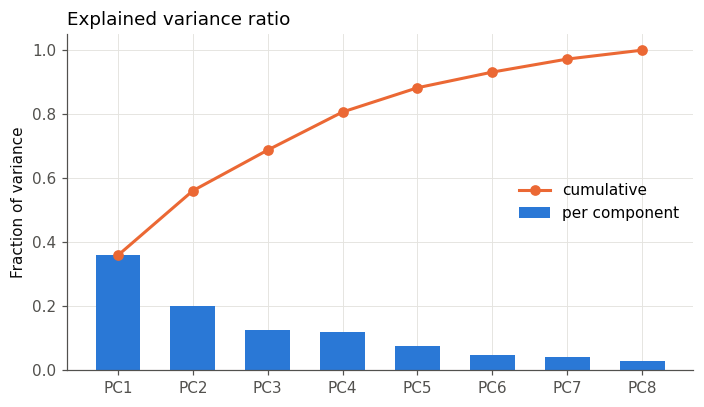

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.arange(len(explained))
ax.bar(x, explained["explained_variance_ratio"], 0.6, color=BLUE, label="per component")
ax.plot(x, explained["cumulative_ratio"], color=ORANGE, lw=2, marker="o", ms=6, label="cumulative")
ax.set_xticks(x); ax.set_xticklabels(explained["component"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Fraction of variance")
ax.set_title("Explained variance ratio")
ax.legend(loc="center right")
fig.tight_layout()
explained.round(4)

## 3. Data and model

Recomputed with the same code and settings as `main.py`.

In [4]:
data = load_data()
names = data["feature_names"]
prep = Preprocessor(names).fit(data["X_reference"])
X_ref, X_qry = prep.transform(data["X_reference"]), prep.transform(data["X_query"])

pca = PCA(n_components=2).fit(X_ref)
Z_ref, Z_qry = pca.transform(X_ref), pca.transform(X_qry)

scorer = PCAAnomalyScorer(pca, quantile=0.95).fit(X_ref)
ref_scores, qry_scores = scorer.reference_scores_, scorer.score(X_qry)
flagged = qry_scores > scorer.threshold_
print(f"threshold = {scorer.threshold_:.4f}, flagged query records = {flagged.sum()} / {len(X_qry)}")

threshold = 19.7148, flagged query records = 37 / 246


## 4. Component coefficients (2b)

PC1 is dominated by conductivity, sulfate and sodium.

,PC1,PC2
conductivity,0.524,-0.012
sodium,0.451,0.194
chloride,0.370,0.296
sulfate,0.455,-0.077
ph,0.377,-0.127
color,-0.188,0.645
turbidity,0.024,0.154
toc,0.015,0.643


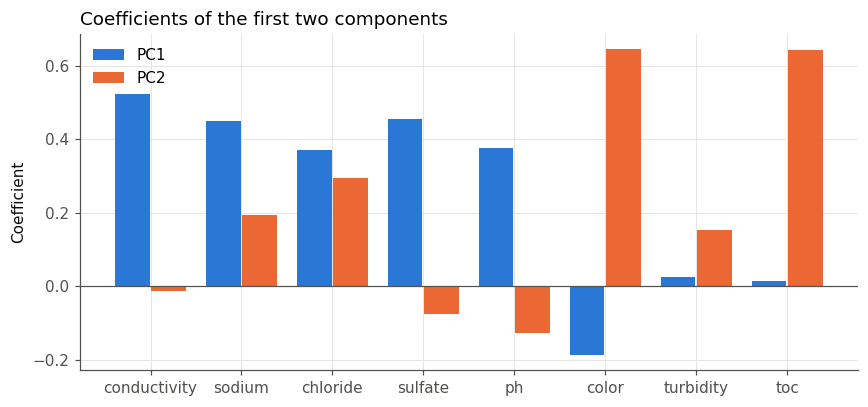

In [5]:
coef = pd.DataFrame(pca.components_, index=names, columns=["PC1", "PC2"])
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(names))
ax.bar(x - 0.2, coef["PC1"], 0.38, color=BLUE, label="PC1")
ax.bar(x + 0.2, coef["PC2"], 0.38, color=ORANGE, label="PC2")
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylabel("Coefficient"); ax.set_title("Coefficients of the first two components")
ax.legend()
fig.tight_layout()
coef.round(3)

## 5. PCA projection (2b)

Flagged query records are circled.

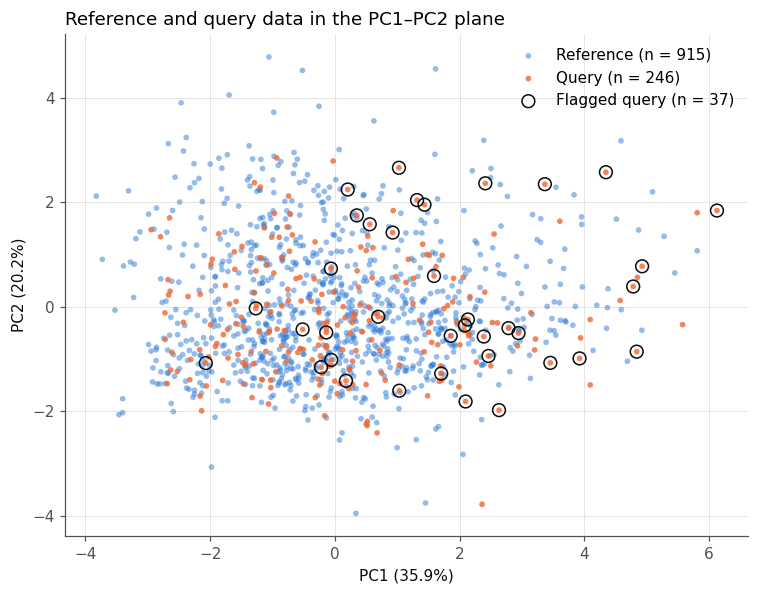

In [6]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(Z_ref[:, 0], Z_ref[:, 1], s=14, color=BLUE, alpha=0.5, edgecolors="none",
           label=f"Reference (n = {len(Z_ref)})")
ax.scatter(Z_qry[:, 0], Z_qry[:, 1], s=14, color=ORANGE, alpha=0.8, edgecolors="none",
           label=f"Query (n = {len(Z_qry)})")
ax.scatter(Z_qry[flagged, 0], Z_qry[flagged, 1], s=70, facecolors="none", edgecolors=TEXT,
           linewidths=1, label=f"Flagged query (n = {flagged.sum()})")
evr = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({100 * evr[0]:.1f}%)"); ax.set_ylabel(f"PC2 ({100 * evr[1]:.1f}%)")
ax.set_title("Reference and query data in the PC1–PC2 plane")
ax.legend(loc="upper right")
fig.tight_layout()

## 6. Anomaly scores (2c, 2d)

The threshold is the 95th percentile of the reference scores; query records with a score strictly above it are flagged.

,reference,query
above threshold,46,37
total,915,246


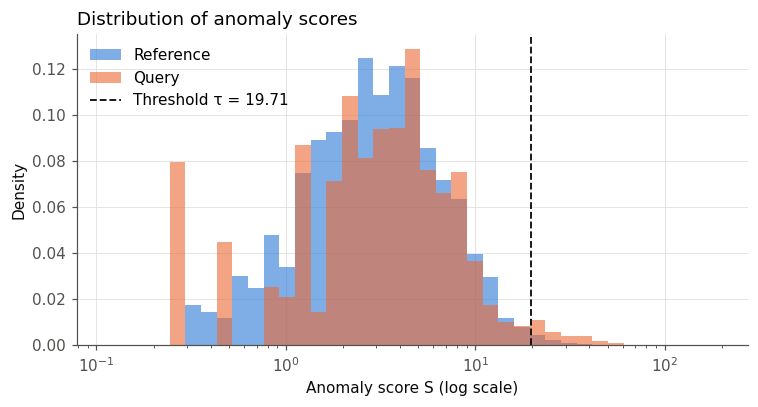

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.logspace(np.log10(min(ref_scores.min(), qry_scores.min())),
                   np.log10(max(ref_scores.max(), qry_scores.max())), 40)
ax.hist(ref_scores, bins=bins, density=True, alpha=0.6, color=BLUE, label="Reference")
ax.hist(qry_scores, bins=bins, density=True, alpha=0.6, color=ORANGE, label="Query")
ax.axvline(scorer.threshold_, color=TEXT, lw=1.2, ls="--",
           label=f"Threshold τ = {scorer.threshold_:.2f}")
ax.set_xscale("log")
ax.set_xlabel("Anomaly score S (log scale)"); ax.set_ylabel("Density")
ax.set_title("Distribution of anomaly scores")
ax.legend()
fig.tight_layout()

pd.DataFrame({"reference": [np.sum(ref_scores > scorer.threshold_), len(ref_scores)],
              "query": [flagged.sum(), len(qry_scores)]},
             index=["above threshold", "total"])

## 7. Ten highest-scoring query records (2d)

In [8]:
top10

,rank,record_id,score,flagged
0,1,Wd0ff3918e355,65.141845,1
1,2,Wda7c4446ab56,59.780691,1
2,3,Wfcd3c52dacfc,55.784846,1
3,4,We39fa2ed29ab,54.434688,1
4,5,We7e67de2c269,47.671309,1
5,6,Wfaca0e1ab9b2,46.361560,1
6,7,Wce50b72ffd36,46.066523,1
7,8,We21615997b66,45.644501,1
8,9,Weef3f9524a87,40.904608,1
9,10,Wfdeae37841c3,40.794480,1


### 7.1 Feature contributions

Standardised residuals r̃ of the top-10 records; the score is the sum of their squares.

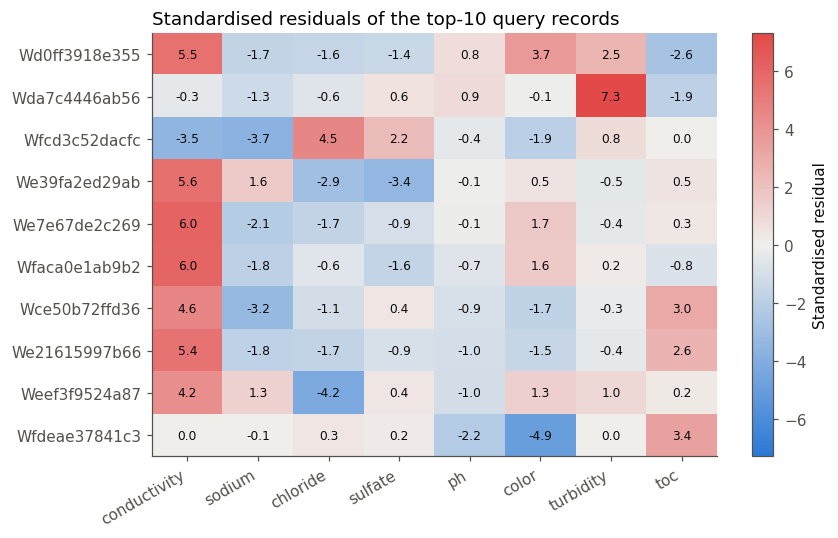

In [9]:
ids = data["record_ids_query"]
idx = [int(np.where(ids == rid)[0][0]) for rid in top10["record_id"]]
R = scorer.standardised_residuals(X_qry)[idx]

fig, ax = plt.subplots(figsize=(8, 5))
lim = np.abs(R).max()
im = ax.imshow(R, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_yticks(range(len(idx))); ax.set_yticklabels(top10["record_id"])
ax.grid(False)
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        ax.text(j, i, f"{R[i, j]:.1f}", ha="center", va="center", fontsize=8, color=TEXT)
fig.colorbar(im, ax=ax, label="Standardised residual")
ax.set_title("Standardised residuals of the top-10 query records")
fig.tight_layout()